In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Import Data
data = pd.read_excel("Data_Padi_Sumatera_Project1.xlsx")
data = data[data['Tahun'] >= 2012]
data.reset_index(drop=True, inplace=True)
data

,Provinsi,Tahun,Produksi,Luas Panen,Curah hujan,Kelembapan,Suhu rata-rata
0,Aceh,2012,1582393.00,387803.00,1098.0,79.60,26.90
1,Aceh,2013,2331046.00,419183.00,1623.6,80.70,27.00
2,Aceh,2014,1820062.00,376137.00,2264.4,78.30,27.10
3,Aceh,2015,1956940.00,461060.00,1575.0,80.00,27.10
4,Aceh,2016,2180754.00,293067.00,1096.0,83.32,27.12
...,...,...,...,...,...,...,...
83,Lampung,2018,2488641.91,511940.93,1385.8,76.05,25.50
84,Lampung,2019,2164089.33,464103.42,1706.4,78.03,27.23
85,Lampung,2020,2604913.29,545149.05,2211.3,75.80,24.58
86,Lampung,2021,2485452.78,489573.23,2110.5,81.77,27.13


In [ ]:
data.isnull().sum()

,0
Provinsi,0
Tahun,0
Produksi,0
Luas Panen,0
Curah hujan,0
Kelembapan,0
Suhu rata-rata,0


In [ ]:
data.duplicated().sum()

0

In [ ]:
data.describe()

,Tahun,Produksi,Luas Panen,Curah hujan,Kelembapan,Suhu rata-rata
count,88.0000,8.800000e+01,88.000000,88.000000,88.000000,88.000000
mean,2017.0000,1.859705e+06,337651.889432,2576.829205,81.753750,26.768977
std,3.1804,1.348091e+06,233301.319641,1016.329507,3.700832,1.294610
min,2012.0000,2.135572e+05,51054.040000,327.330000,71.220000,22.190000
25%,2014.0000,5.693620e+05,107168.750000,1784.900000,79.575000,26.397500
50%,2017.0000,1.840815e+06,312361.025000,2330.300000,81.900000,26.835000
75%,2020.0000,2.690339e+06,504284.750000,3241.725000,83.855000,27.135000
max,2022.0000,4.881089e+06,872737.000000,5332.300000,98.750000,34.350000


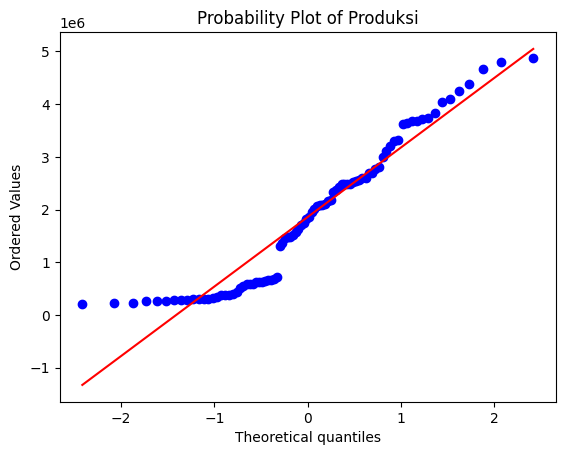

In [ ]:
from scipy import stats

produksi = data['Produksi']
stats.probplot(produksi, dist="norm", plot=plt)
plt.title(f'Probability Plot of Produksi')
plt.show()

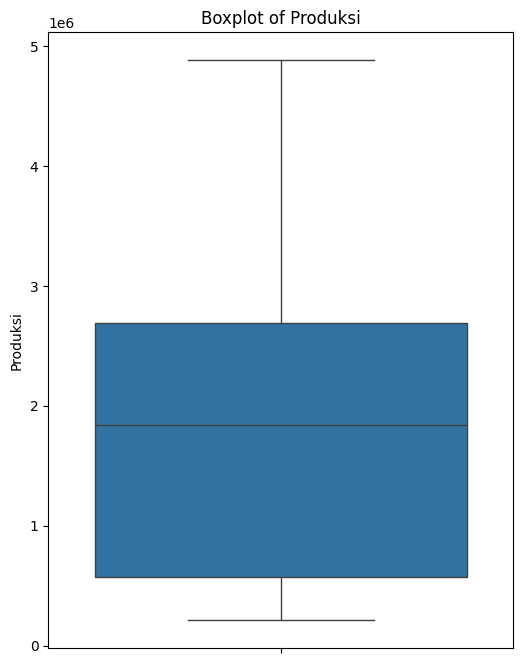

In [ ]:
plt.figure(figsize=(6, 8))
sns.boxplot(y='Produksi', data=data, orient='v')
plt.title('Boxplot of Produksi')
plt.show()

In [ ]:
df = data.drop(columns=['Tahun', 'Provinsi'], axis=1)
df

,Produksi,Luas Panen,Curah hujan,Kelembapan,Suhu rata-rata
0,1582393.00,387803.00,1098.0,79.60,26.90
1,2331046.00,419183.00,1623.6,80.70,27.00
2,1820062.00,376137.00,2264.4,78.30,27.10
3,1956940.00,461060.00,1575.0,80.00,27.10
4,2180754.00,293067.00,1096.0,83.32,27.12
...,...,...,...,...,...
83,2488641.91,511940.93,1385.8,76.05,25.50
84,2164089.33,464103.42,1706.4,78.03,27.23
85,2604913.29,545149.05,2211.3,75.80,24.58
86,2485452.78,489573.23,2110.5,81.77,27.13


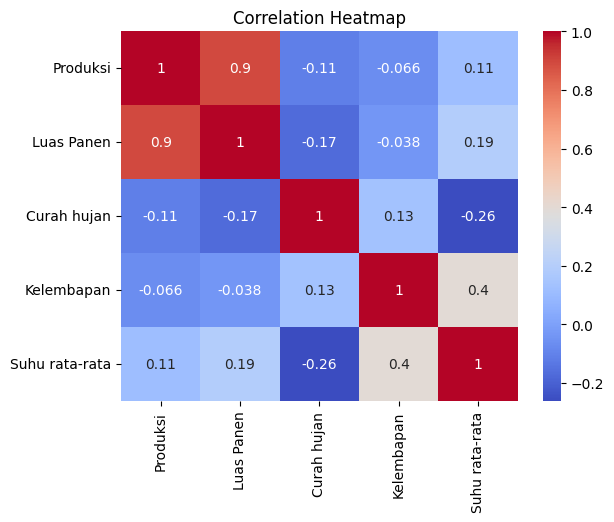

In [ ]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
x = df[['Luas Panen', 'Curah hujan', 'Kelembapan', 'Suhu rata-rata']]
y = df['Produksi']

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_x = StandardScaler()
scaler_y = StandardScaler()
x_scaled = scaler_x.fit_transform(x)
y_scaled = scaler_y.fit_transform(y.values.reshape(-1, 1))
print(x_scaled[:5])
print(y_scaled[:5])

[[ 0.21619471 -1.46340722 -0.5852988   0.10178628]
 [ 0.35146969 -0.94328845 -0.286365    0.17947225]
 [ 0.16590415 -0.30917103 -0.93858421  0.25715822]
 [ 0.53199582 -0.99138162 -0.4765956   0.25715822]
 [-0.19219948 -1.46538636  0.42564098  0.27269542]]
[[-0.2068859 ]
 [ 0.35163976]
 [-0.02957514]
 [ 0.07254143]
 [ 0.2395158 ]]


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

x_train, x_test, y_train, y_test = train_test_split(x_scaled, y_scaled, test_size=0.2, random_state=42)
print('x_train:', x_train.shape)
print('x_test: ', x_test.shape)
print('y_train:', y_train.shape)
print('y_test: ', y_test.shape)

x_train: (70, 4)
x_test:  (18, 4)
y_train: (70, 1)
y_test:  (18, 1)


In [ ]:
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
linreg.fit(x_train, y_train)

LinearRegression()

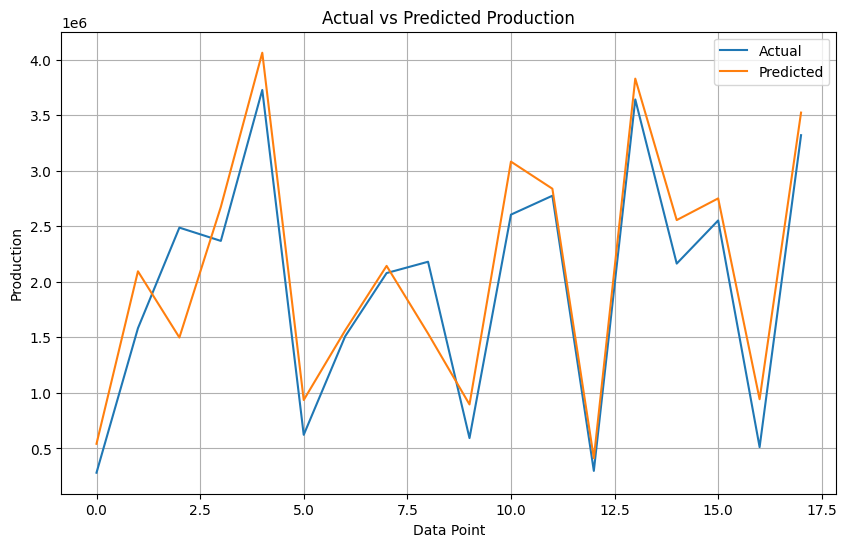

In [ ]:
y_pred_linreg = linreg.predict(x_test)
y_pred_linreg_inv = scaler_y.inverse_transform(y_pred_linreg)
y_test_inv = scaler_y.inverse_transform(y_test)

# Create the line plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(y_test_inv)), y_test_inv, label='Actual')
plt.plot(range(len(y_pred_linreg_inv)), y_pred_linreg_inv, label='Predicted')
plt.xlabel('Data Point')
plt.ylabel('Production')
plt.title('Actual vs Predicted Production')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
comparison_df = pd.DataFrame({'Actual': y_test_inv.flatten(), 'Predicted (LinReg)': y_pred_linreg_inv.flatten()})
styled_df = comparison_df.style.format({'Actual': '{:.2f}', 'Predicted (LinReg)': '{:.2f}'})
display(styled_df)

,Actual,Predicted (LinReg)
0,281610.10,541902.55
1,1582393.00,2094751.73
2,2487929.00,1498759.78
3,2368390.00,2674255.82
4,3727249.00,4062353.72
5,622832.00,936105.21
6,1509456.00,1562611.94
7,2078901.59,2143484.64
8,2180754.00,1534451.23
9,593194.00,896229.37


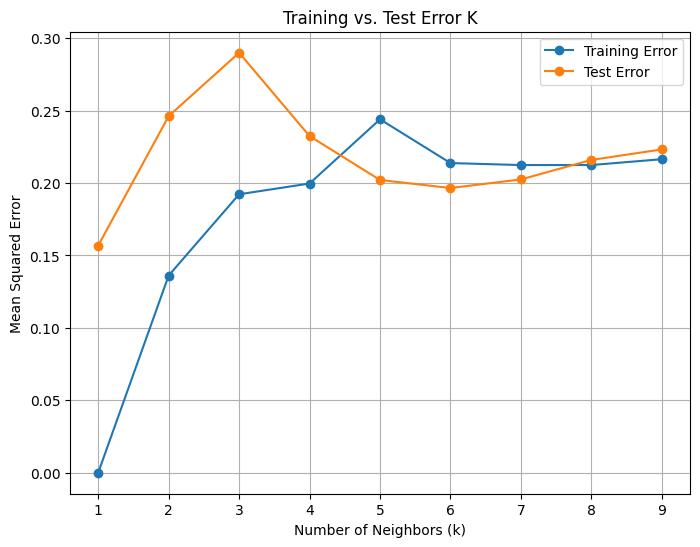

In [ ]:
k_values = range(1, 10)

train_errors = []
test_errors = []

for k in k_values:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(x_train, y_train)

    # Predict on training and testing sets
    y_train_pred = knn.predict(x_train)
    y_test_pred = knn.predict(x_test)

    # Calculate MSE for both sets
    train_errors.append(mean_squared_error(y_train, y_train_pred))
    test_errors.append(mean_squared_error(y_test, y_test_pred))

# Plot the errors
plt.figure(figsize=(8, 6))
plt.plot(k_values, train_errors, label="Training Error", marker='o')
plt.plot(k_values, test_errors, label="Test Error", marker='o')
plt.title("Training vs. Test Error K")
plt.xlabel("Number of Neighbors (k)")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid()
plt.show()


In [ ]:
from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor(n_neighbors=6)
knn.fit(x_train, y_train)

KNeighborsRegressor(n_neighbors=6)

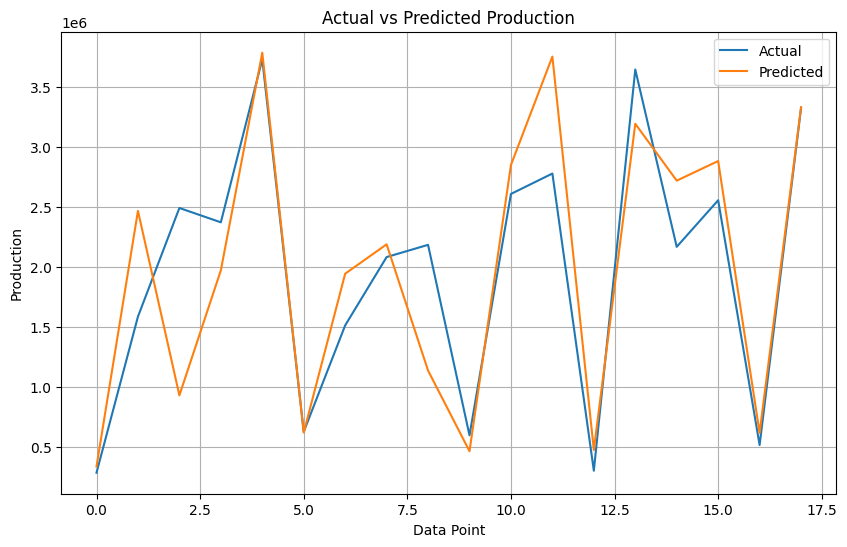

In [ ]:
y_pred_knn = knn.predict(x_test)
y_pred_knn_inv = scaler_y.inverse_transform(y_pred_knn)
y_test_inv = scaler_y.inverse_transform(y_test)

# Create the line plot
plt.figure(figsize=(10, 6))
plt.plot(range(len(y_test_inv)), y_test_inv, label='Actual')
plt.plot(range(len(y_pred_knn_inv)), y_pred_knn_inv, label='Predicted')
plt.xlabel('Data Point')
plt.ylabel('Production')
plt.title('Actual vs Predicted Production')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
comparison_df = pd.DataFrame({'Actual': y_test_inv.flatten(), 'Predicted (KNN)': y_pred_knn_inv.flatten()})
comparison_df
styled_df = comparison_df.style.format({'Actual': '{:.2f}', 'Predicted (KNN)': '{:.2f}'})
display(styled_df)

,Actual,Predicted (KNN)
0,281610.10,333647.66
1,1582393.00,2463872.25
2,2487929.00,926457.75
3,2368390.00,1967896.79
4,3727249.00,3781890.64
5,622832.00,616342.68
6,1509456.00,1940206.64
7,2078901.59,2185080.93
8,2180754.00,1132968.67
9,593194.00,460930.90


In [ ]:
r2_linreg = r2_score(y_test, y_pred_linreg)
mae_linreg = mean_absolute_error(y_test_inv, y_pred_linreg_inv)
mse_linreg = mean_squared_error(y_test_inv, y_pred_linreg_inv)
r2_knn = r2_score(y_test_inv, y_pred_knn_inv)
mae_knn = mean_absolute_error(y_test_inv, y_pred_knn_inv)
mse_knn = mean_squared_error(y_test_inv, y_pred_knn_inv)

score = {'Model': ['Linear Regression', 'KNN'], 'R2 Score': [r2_linreg, r2_knn], 'MAE': [mae_linreg, mae_knn], 'MSE': [mse_linreg, mse_knn]}
score = pd.DataFrame(score)
print(score)

               Model  R2 Score            MAE           MSE
0  Linear Regression  0.868181  324967.053821  1.571551e+11
1                KNN  0.703748  416812.345648  3.531935e+11


In [ ]:
datanew = {'Produksi': 2832770, 'Luas Panen': 504140, 'Curah hujan': 27.88, 'Kelembapan': 81.32, 'Suhu rata-rata': 10.42}
datanew = pd.DataFrame([datanew])
x_new = datanew.drop(columns='Produksi', axis=1)
y_new = datanew['Produksi']

x_new_scaled = scaler_x.transform(x_new)
y_new_scaled = scaler_y.transform(y_new.values.reshape(-1, 1))

y_pred_linreg_scaled = linreg.predict(x_new_scaled)
y_linreg_pred = scaler_y.inverse_transform(y_pred_linreg_scaled.reshape(-1, 1))

y_pred_knn_scaled = knn.predict(x_new_scaled)
y_knn_pred = scaler_y.inverse_transform(y_pred_knn_scaled.reshape(-1, 1))

print(f'Actual: {datanew["Produksi"][0]}')
print(f'Predicted Linear Regression: {y_linreg_pred[0][0]}')
print(f'Predicted KNN: {y_knn_pred[0][0]}')

Actual: 2832770
Predicted Linear Regression: 2822234.1693238975
Predicted KNN: 2003718.2583333333
